In [1]:
# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Import data
obs = pd.read_csv('data/55_Hare_Data_2012.txt')

# View DataFrame
obs.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [2]:
obs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [3]:
obs['date'] = pd.to_datetime(obs['date'])
print(obs['date'].dtype)

datetime64[ns]


In [4]:
## Examine the hares age data
obs['age'].value_counts(dropna=False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

When a decision, document it. 
We will keep all hares with a j as juvenile, and all hares with a as an adult

In [13]:
# update age values to juvenile for observations where 'a' and 'j' are included
obs.loc[obs['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile'
obs['age'].value_counts()

age
adults       759
juvenile     396
1/2/2013      21
1/4/2013      21
3/4/2013      18
1             12
U             11
?             10
2 yrs.         3
u              3
1.5            2
3.5 yrs.       2
2.25 yrs       2
1 yr.          2
1 yr           2
2.5 yrs        1
3 yrs.         1
2 yrs          1
1.25           1
3.25 yrs.      1
Name: count, dtype: int64

In [14]:
# update age values to adult for observations where 'a' and 'j' are included
obs.loc[obs['age'].str.contains('a', case=False, na=False), 'age'] = 'adult'
obs['age'].value_counts()

age
adult        759
juvenile     396
1/2/2013      21
1/4/2013      21
3/4/2013      18
1             12
U             11
?             10
2 yrs.         3
u              3
1.5            2
3.5 yrs.       2
2.25 yrs       2
1 yr.          2
1 yr           2
2.5 yrs        1
3 yrs.         1
2 yrs          1
1.25           1
3.25 yrs.      1
Name: count, dtype: int64

In [15]:
# filter for confirmed observations of juveniles and adult hares
obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])].copy()
print('Number of juvenile and adult hare observations (captures):', len(obs_juv_adult))

Number of juvenile and adult hare observations (captures): 1155


In [17]:
# Extract year in which ach observations  happened 
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year
obs_juv_adult.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study,year
108,1999-06-23,NaN,bonrip,2C,68,69,M,juvenile,395.0,126.0,NaN,643.0,53,Population,1999
109,1999-06-23,NaN,bonrip,2E,70,71,F,juvenile,420.0,137.0,NaN,653.0,53,Population,1999
110,1999-06-23,NaN,bonrip,3D,72,73,M,juvenile,445.0,144.0,NaN,944.0,53,Population,1999
111,1999-06-23,NaN,bonrip,4B,76,77,M,juvenile,410.0,115.0,NaN,663.0,53,Population,1999
112,1999-06-23,NaN,bonrip,4C,78,79,M,juvenile,430.0,132.0,NaN,670.0,53,Population,1999


In [20]:
# Count observations per year and age, then move age values into column
obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack()
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


In [22]:
obs_per_year.index

Index([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
       2011, 2012],
      dtype='int32', name='year')

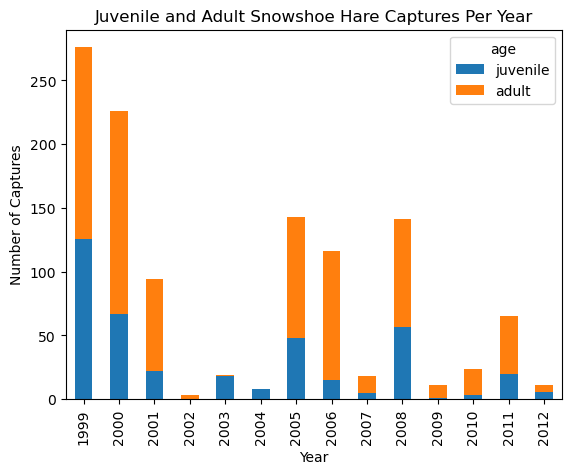

In [24]:
obs_per_year[['juvenile', 'adult']].plot(kind = 'bar', stacked= True, title = 'Juvenile and Adult Snowshoe Hare Captures Per Year', 
                                         xlabel = 'Year',
                                         ylabel = 'Number of Captures');

## Plotting with matplotlib

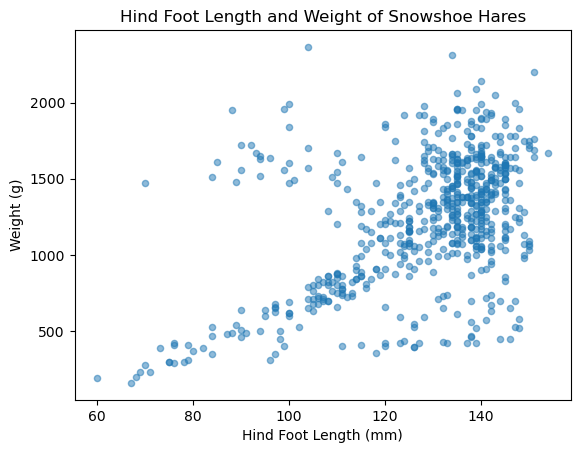

In [ ]:
# initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# add a scatter plot of hares data to our figures axes 
obs_juv_adult.plot(kind = 'scatter', x = 'hindft', y = 'weight', ax = ax, alpha = 0.5)

# update axes 
ax.set_title('Hind Foot Length and Weight of Snowshoe Hares')
ax.set_xlabel('Hind Foot Length (mm)')
ax.set_ylabel('Weight (g)')

# Display
plt.show()

## Linear regression

for our analysis we want to investigate possible relations between hind foot length and weight for juvenile hares.

In [30]:
juv_w_hft = obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

Number of Observations 265


<Axes: xlabel='hindft', ylabel='weight'>

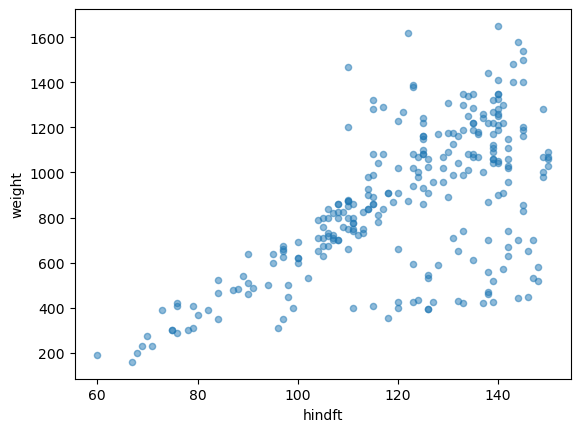

In [31]:
print('Number of Observations', len(juv_w_hft))
juv_w_hft.plot.scatter(x = 'hindft', y = 'weight', alpha = 0.5)

In [34]:
# Fit a model: weight explained by hind foot length 
model = smf.ols('weight ~ hindft', data=juv_w_hft).fit()

In [ ]:
# view model summary
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [36]:

# retrieve parameters
intercept = model.params['Intercept']
print('y-intercept:', intercept)

slope = model.params['hindft']
print('slope: ', slope)

y-intercept: -352.77198564640645
slope:  10.092239638623006


In [ ]:
print('R^2: ', model.rsquared)
# this is the coefficient of determination. It is between 0 - 1 and if it is 1 then it is a perfect fit of the model to the data. 
# we interpret it as the proportion of variance in the response that is explained by the least sqaures line with the predictor variable.

R^2:  0.3871164783665738


In [40]:
# smallest and largest hind foot lengths
x_start = juv_w_hft['hindft'].min()
x_end = juv_w_hft['hindft'].max()
print(x_start, x_end)

60.0 150.0


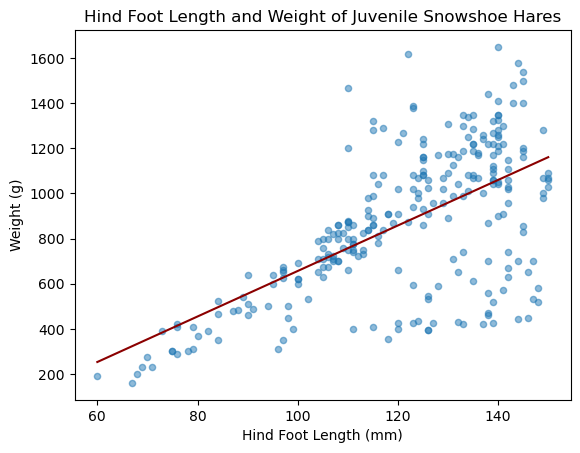

In [41]:
# Plot the Model
# initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# add a scatter plot of hares data to our figures axes 
juv_w_hft.plot(kind = 'scatter', x = 'hindft', y = 'weight', ax = ax, alpha = 0.5)

# Add regression line to axes
ax.plot([x_start, x_end], [intercept + slope * x_start, intercept + slope * x_end], color = 'darkred')

# update axes 
ax.set_title('Hind Foot Length and Weight of Juvenile Snowshoe Hares')
ax.set_xlabel('Hind Foot Length (mm)')
ax.set_ylabel('Weight (g)')

# Display
plt.show()

In [43]:
model.resid

108    -523.850209
109    -609.864845
110    -655.510522
111    -397.835573
112    -549.403647
           ...    
3355    -46.820937
3359    117.625625
3360    117.625625
3367   -276.175259
3369    -37.189895
Length: 265, dtype: float64

<Axes: title={'center': 'Distribution of residuals'}, xlabel='Residual (g)', ylabel='Frequency'>

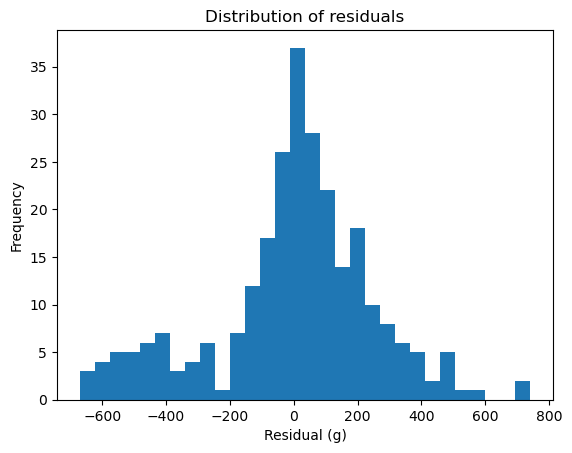

In [44]:
model.resid.plot(kind='hist', 
                 bins=30, 
                 title='Distribution of residuals', 
                 xlabel='Residual (g)')

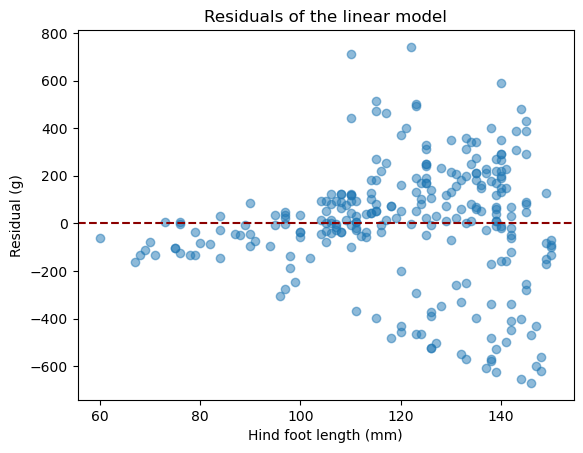

In [ ]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add residuals to axes
ax.scatter(juv_w_hft['hindft'], model.resid, alpha=0.5)

# Add reference line at 0
ax.axhline(0, color='darkred', linestyle='--')

# Update axes
ax.set_title('Residuals of the linear model')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Residual (g)')

# Display figure
plt.show()